# Análise do ID3 para PopOut

## Objetivos da análise
Pretendemos analisar o algoritmo ID3 por nós desenvolvido em três frentes:
- Performance preditiva num dataset simples de teste (iris)
- Performance preditiva num dataset gerado pelo MCTS para o jogo PopOut
- Capacidade para jogar PopOut contra humanos, MCTS, e outras instâncias de si mesmo

> Nota:
Todos os ficheiros referidos neste notebook encontram-se na diretório decision_tree

## Implementação do algoritmo

O ID3 (Iterative Dichotomiser 3) é um algoritmo de aprendizagem supervisionada que constrói árvores de decisão de forma recursiva. A cada passo, escolhe o atributo que melhor separa os dados com base no **Ganho de Informação** (*Information Gain*), usando a **Entropia** como medida de impureza.

### Entropia

A entropia (metrics.py -> get_enthropy) mede o grau de desordem de um conjunto de dados. Para uma variável alvo $y$ com classes $c_1, c_2, \dots, c_n$, a entropia é:

$$
H(y) = -\sum_{i=1}^{n} p_i \log_2(p_i)
$$

onde $p_i$ é a proporção de exemplos da classe $c_i$ no conjunto.
Valores próximos de $0$ indicam conjuntos puros (uma só classe); valores próximos de $\log_2(n)$ indicam máxima dispersão.

### Ganho de Informação

O Ganho de Informação (metrics.py -> calculate_information_gain) mede a redução da entropia ao particionar os dados pelo atributo $X$:

$$
IG(y, X) = H(y) - \sum_{v \in \text{vals}(X)} \frac{|y_{X=v}|}{|y|} \cdot H(y_{X=v})
$$

O algoritmo seleciona o atributo (e, no caso numérico, o ponto de corte) que maximiza $IG$.

### Tratamento de atributos numéricos

O código testa pontos de corte a meio dos valores consecutivos ordenados (id3.py > _get_best_split):

$$
\text{possible\_splits} = \frac{\text{unique\_vals}[1:] + \text{unique\_vals}[:-1]}{2}
$$

Para cada split candidato, os dados são divididos em $X \leq split$ e $X > split$, calculando-se o IG. Atributos inteiros com 4 ou menos valores únicos são tratados como categóricos (auxiliar.py -> is_numeric).

### Critérios de paragem

A construção recursiva da árvore termina quando:

- O conjunto de dados está vazio (todas as *features* foram usadas);
- A profundidade máxima (`max_depth`) é atingida;
- O número de amostras é inferior a `min_samples`.

Nestes casos, o nó torna-se folha e devolve a classe maioritária do subconjunto.

### Previsão para o jogo PopOut

O método `predict_valid()` foi adaptado para o cenário de jogo: percorre a árvore até uma folha e, se a classe prevista não for uma jogada válida, sobe na árvore até encontrar um nó cuja classe maioritária seja válida. Se nenhum nó tiver uma classe válida, escolhe aleatoriamente.

### Parâmetros

| Parâmetro | Descrição |
|-----------|-----------|
| `max_depth` | Profundidade máxima da árvore (se igual a None, não existe profundidade máxima) |
| `min_samples` | Número mínimo de amostras para continuar a dividir |

## 1 - Performance preditiva no dataset iris
O principal objetivo deste teste é verificar o correto funcionamento do algoritmo, visto tratar-se de um dataset bastante simples

In [77]:
%load_ext autoreload
%autoreload 2

import sys
import os
from pathlib import Path
sys.path.append(os.path.abspath(".."))

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [78]:
df = pd.read_csv(Path("..", "data", "iris.csv"))
df.head()

,ID,sepallength,sepalwidth,petallength,petalwidth,class
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [79]:
X = df.drop("class", axis=1)
y=df["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [80]:
from decision_tree import id3
tree = id3.ID3() #no arguments, min_samples=10 and max_depth=None
tree.fit(X_train, y_train)

In [81]:
y_pred = tree.predict(X_test)
print("Accuracy: ", accuracy_score(y_test, y_pred))
#o carlos soares deve-nos um jantar

Accuracy:  1.0


O modelo acertou em todos os (50) casos de teste. Dado o tamanho reduzido do dataset e a sua simplicidade isto não constitui uma grande surpresa.

In [82]:
tree.print_tree()

└─ Root  --->  [Split: Feature ID]
    └─ If Feature ID < 100.50  --->  [Split: Feature petallength]
        └─ If Feature petallength < 2.45  --->  Predict: Iris-setosa
        └─ If Feature petallength >= 2.45  --->  Predict: Iris-versicolor
    └─ If Feature ID >= 100.50  --->  Predict: Iris-virginica


Podemos ver que, apesar de não limitarmos a profundidade máxima da árvore, a sua complexidade não é muito elevada.

## 2 - Performance preditiva no dataset PopOut

O dataset MCTS (`data/dataset_mcts.csv`) foi gerado pelo MCTS durante partidas de PopOut. Contém ~21k estados de jogo, cada um representado por 42 features (`pos_0` a `pos_41`), correspondentes às posições do tabuleiro 6×7 (valores -1, 0, 1 para peças do oponente, vazio, peças do agente). O target é a `move` (coluna onde jogar, 0–13).

### Processo de treino

As árvores foram treinadas com o script `scripts/train_id3.py`, seguindo os passos:

- Split 90/10 treino-teste com `random_state=42`;
- Grid search sobre hiperparâmetros:
   - `max_depth ∈ {None, 5, 10, 50, 100}`
   - `min_samples ∈ {1, 2, 5, 10, 20, 50}`
- 30 árvores treinadas com `ID3().fit()` e guardadas em `decision_tree/pre_trained_trees/`;
- *Accuracy* calculada com `accuracy_score(y_test, y_pred)` para cada combinação.

Os resultados foram registados no ficheiro `job_1258163.out`.

In [83]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [84]:
df = pd.read_csv(Path("..", "data", "dataset_mcts.csv"))
print("Dimensão:", df.shape)
df.head()

Dimensão: (21110, 43)


,pos_0,pos_1,pos_2,pos_3,pos_4,pos_5,pos_6,pos_7,pos_8,pos_9,...,pos_33,pos_34,pos_35,pos_36,pos_37,pos_38,pos_39,pos_40,pos_41,move
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,5
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,2
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,3


In [85]:
print("Distribuição dos targets:")
print(df["move"].value_counts().sort_index())
print(f"\nNúmero de classes: {df['move'].nunique()}")
print(f"Baseline aleatório: {1/df['move'].nunique():.1%}")

Distribuição dos targets:
move
0     1411
1     2738
2     3662
3     3783
4     3617
5     2590
6     1255
7       97
8      297
9      415
10     476
11     431
12     258
13      80
Name: count, dtype: int64

Número de classes: 14
Baseline aleatório: 7.1%


In [86]:
# Resultados extraídos do job_1258163.out
results = [
    (None, 1, 0.32780672666982474),
    (None, 2, 0.32780672666982474),
    (None, 5, 0.3192799621032686),
    (None, 10, 0.324964471814306),
    (None, 20, 0.3410705826622454),
    (None, 50, 0.3481762198010422),
    (5, 1, 0.33728090952155376),
    (5, 2, 0.33728090952155376),
    (5, 5, 0.33728090952155376),
    (5, 10, 0.3377546186641402),
    (5, 20, 0.3387020369493131),
    (5, 50, 0.3415442918048318),
    (10, 1, 0.324964471814306),
    (10, 2, 0.324964471814306),
    (10, 5, 0.319753671245855),
    (10, 10, 0.32354334438654664),
    (10, 20, 0.3410705826622454),
    (10, 50, 0.3481762198010422),
    (50, 1, 0.32780672666982474),
    (50, 2, 0.32780672666982474),
    (50, 5, 0.3192799621032686),
    (50, 10, 0.324964471814306),
    (50, 20, 0.3410705826622454),
    (50, 50, 0.3481762198010422),
    (100, 1, 0.32780672666982474),
    (100, 2, 0.32780672666982474),
    (100, 5, 0.3192799621032686),
    (100, 10, 0.324964471814306),
    (100, 20, 0.3410705826622454),
    (100, 50, 0.3481762198010422),
]

df_results = pd.DataFrame(results, columns=["max_depth", "min_samples", "accuracy"])
df_results["max_depth"] = df_results["max_depth"].apply(lambda x: "None" if x is None else str(x))
df_results = df_results.sort_values("accuracy", ascending=False).reset_index(drop=True)
df_results["accuracy"] = df_results["accuracy"].apply(lambda x: f"{x:.2%}")
df_results

,max_depth,min_samples,accuracy
0,100.0,50,34.82%
1,nan,50,34.82%
2,50.0,50,34.82%
3,10.0,50,34.82%
4,5.0,50,34.15%
5,nan,20,34.11%
6,100.0,20,34.11%
7,50.0,20,34.11%
8,10.0,20,34.11%
9,5.0,20,33.87%


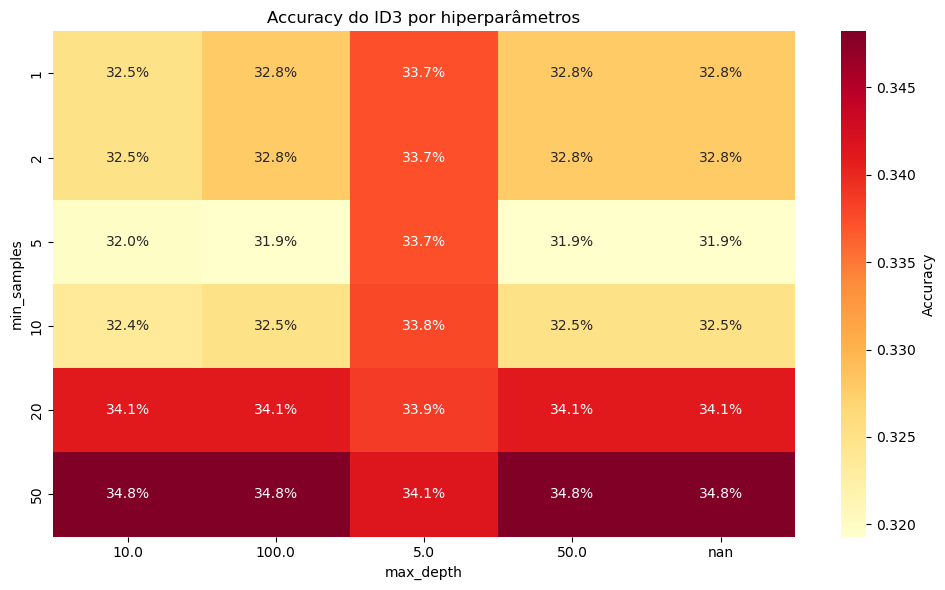

In [87]:
# Heatmap: max_depth vs min_samples
pivot = df_results.copy()
pivot["accuracy"] = pivot["accuracy"].str.rstrip("%").astype(float) / 100
pivot = pivot.pivot_table(
    values="accuracy",
    index="min_samples",
    columns="max_depth",
    aggfunc="first"
)

plt.figure(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".1%", cmap="YlOrRd", cbar_kws={"label": "Accuracy"})
plt.title("Accuracy do ID3 por hiperparâmetros")
plt.ylabel("min_samples")
plt.xlabel("max_depth")
plt.tight_layout()
plt.show()

### Discussão

A melhor combinação atinge ~34.8% de accuracy, o que é cerca de 5× melhor que o baseline aleatório de ~7.1% (14 classes).

Observações:
- `max_depth` acima de 5 não traz melhorias significativas — o dataset pode não requerer árvores muito profundas para capturar os padrões relevantes.
- `min_samples` mais altos (50) tendem a melhorar ligeiramente a accuracy, sugerindo que a regularização ajuda a evitar overfitting.
- Os resultados são consistentes entre `max_depth` = None, 50 e 100 para o mesmo `min_samples`, indicando que a árvore raramente ultrapassa a profundidade 50.

Note-se que a accuracy padrão (acertar na coluna exata) é uma métrica exigente. No ponto 3, o método `predict_valid` mitiga este problema ao subir na árvore até encontrar uma jogada válida, tornando o modelo mais robusto para o contexto do jogo.